# 03 — Forecast nursing PPE and show uncertainty

The last observation is October 2026. We forecast **November and December 2026** with the final SARIMA model and show approximate 95% prediction intervals.

For perspective, we also calculate what the three simple rules would predict over those same months. Only the SARIMA interval is shown: the simple benchmark rules do not provide comparable model-based intervals in this exercise.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
assert (ROOT / "data").exists(), "Run Jupyter from the project root or notebooks/ folder."
sys.path.insert(0, str(ROOT))

import json
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAXResults
from src.ppe_forecasting import (
    load_monthly_series, build_prediction_frame, naive_forecast,
    seasonal_naive_forecast, moving_average_forecast
)
history = load_monthly_series(ROOT / "data/processed/nursing_workforce_monthly.csv")
metadata = json.loads((ROOT / "outputs/reports/model_metadata.json").read_text(encoding="utf8"))
assert metadata["history_end"] == history.index.max().strftime("%Y-%m-%d"), "Train again if data changed"
# Only load model files you generated locally; serialized models are not safe if untrusted.
model = SARIMAXResults.load(ROOT / "outputs/models/nursing_sarima_results.pkl")
HORIZON = 2

## 1. Generate two-month forecasts

The point forecast is a best estimate under the model. Its **approximately 95% prediction interval** makes uncertainty visible, though it does not guarantee that future outcomes will fall within the bounds.

In [2]:
forecast = build_prediction_frame(model, history.index.max(), HORIZON)
forecast["last_value"] = naive_forecast(history, HORIZON)
forecast["same_month_last_year"] = seasonal_naive_forecast(history, HORIZON)
forecast["last_3_month_average"] = moving_average_forecast(history, HORIZON)
display(forecast.round(2))

,month,ppe_forecast,lower_95,upper_95,last_value,same_month_last_year,last_3_month_average
0,2026-11-30,1557.11,1532.00,1582.23,1541.92,1502.71,1550.52
1,2026-12-31,1565.36,1538.32,1592.39,1541.92,1512.07,1550.52


## 2. Visualize the result

All observations and forecasts in this repository are **synthetic**. The comparison in notebook 02, not this future chart, is where predictive accuracy is measured.

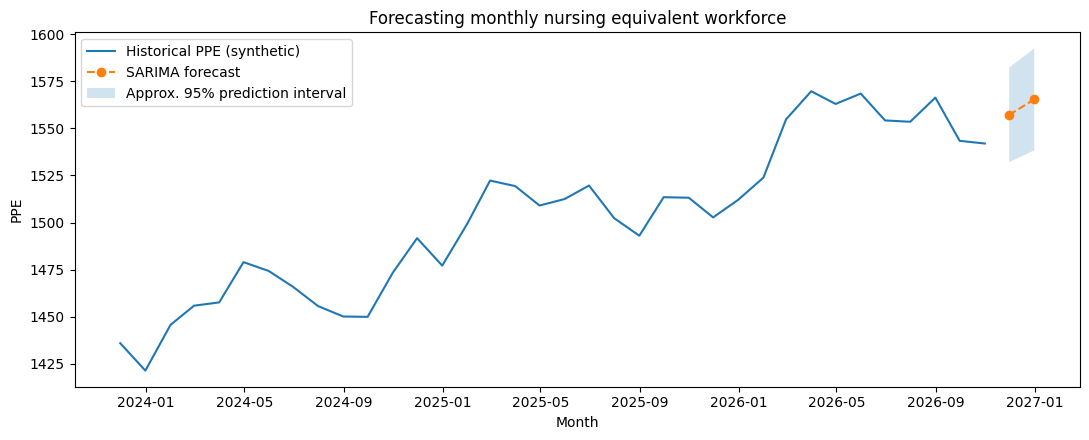

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(history.index[-36:], history.iloc[-36:], label="Historical PPE (synthetic)")
ax.plot(forecast["month"], forecast["ppe_forecast"], marker="o", linestyle="--", label="SARIMA forecast")
ax.fill_between(forecast["month"], forecast["lower_95"], forecast["upper_95"],
                alpha=0.2, label="Approx. 95% prediction interval")
ax.set(title="Forecasting monthly nursing equivalent workforce", xlabel="Month", ylabel="PPE")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "outputs/figures/04_future_forecast.png", dpi=150)
plt.show()

## 3. Export a small table

The exported CSV includes the SARIMA prediction, its interval and the three simple alternatives. It is a reproducible **illustration**, not a forecast for any real hospital.

In [4]:
export_path = ROOT / "outputs/reports/nursing_workforce_forecast_synthetic.csv"
forecast.to_csv(export_path, index=False, float_format="%.3f")
print("Exported:", export_path.relative_to(ROOT))

Exported: outputs/reports/nursing_workforce_forecast_synthetic.csv
